<a href="https://colab.research.google.com/github/sumitgiri35885-rgb/AI-Based-Traffic-Congestion-Incident-Detection-Using-Aerial-Imagery/blob/main/AI_Based_Traffic_Congestion_%26_Incident_Detection_Using_Aerial_Imagery.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

url = "https://docs.google.com/spreadsheets/d/1z5WFArY9DnSyq854vktucDPxs6qvx8sYEDViOfVMp4M/export?format=csv"
df = pd.read_csv(url)
print(df.head())


   vehicle_density  avg_vehicle_speed  speed_std  lane_occupancy  \
0        23.865083          56.660004   5.737366        0.448821   
1        15.755624          67.562554   3.761696        0.203759   
2        14.719641          60.782993   3.558324        0.259485   
3        14.719814          72.431960   0.560680        0.210146   
4        43.372854          33.125925  12.071894        0.685767   

   queue_length  edge_density  optical_flow_mag  shadow_fraction  \
0     13.583201      0.412864          0.395673         0.127440   
1      9.119581      0.343221          0.877234         0.197382   
2      6.966499      0.336209          0.455082         0.196271   
3      4.188474      0.277365          0.730398         0.090561   
4      9.363837      0.643574          0.210252         0.140736   

   time_of_day_norm  road_width_norm  label  
0          0.334763         0.990240      1  
1          0.688851         0.663392      0  
2          0.279968         0.905470      0 

#Task 1: Data Understanding

#Average Vehicle Speed
 1) indicates how fast vehicles are moving. Lower speeds often signal congestion or road incidents.

#Vehicle Density  
 1)Measures the number of vehicles per road segment. High density suggests traffic buildup and potential jams

#Lane Occupancy
1) Shows how much of a lane is filled. High occupancy values indicate bottlenecks or heavy usage.

#Queue Length  
1)Represents the number of vehicles waiting. Longer queues are strong indicators of congestion at signals or due to accidents.

#Optical Flow Magnitude
1)Captures motion patterns from aerial imagery. Sudden drops in flow may indicate stalled traffic or incidents.

#Edge Density  
1)Helps detect vehicles in aerial images by measuring visual edges. Useful for confirming congestion visually.

#Time-of-Day Normalization
1)Adjusts traffic features to account for natural variations rush hour vs. off-peak. Prevents bias in detection.

#Illumination Effects
1)Corrects for lighting changes (day/night, shadows) so congestion detection remains accurate under different conditions.


Precision: 0.8483685220729367
Recall: 0.8185185185185185
F1-score: 0.8331762488218661
ROC-AUC: 0.9259918630751964


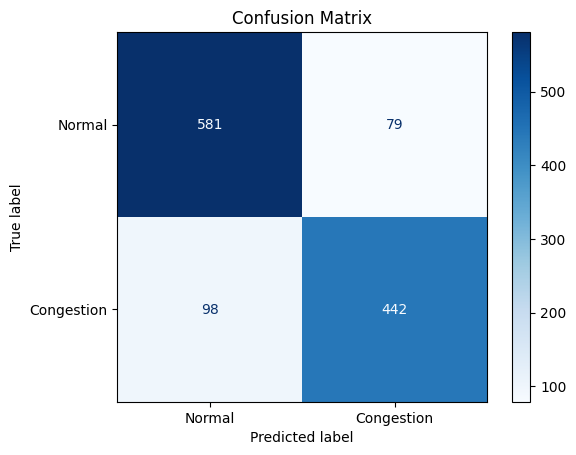

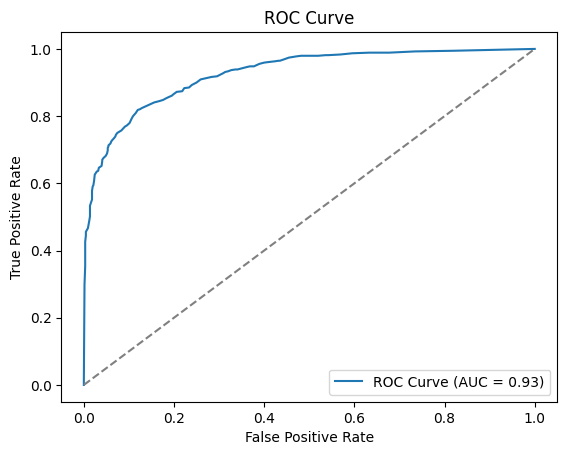

In [ ]:
# Task 2: Machine Learning Model

# Step 1: Import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, confusion_matrix,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Step 2: Load dataset
df= pd.read_csv(url)

# Step 3: Separate features and labels
X = df.drop("label", axis=1)   # Features
y = df["label"]                # Target (0 = normal, 1 = congestion/incident)

# Step 4: Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Step 5: Train model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Step 6: Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

# Step 7: Evaluation metrics
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("ROC-AUC:", roc_auc)

# Step 8: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Congestion"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# Step 9: ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.2f})")
plt.plot([0,1],[0,1],"--",color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


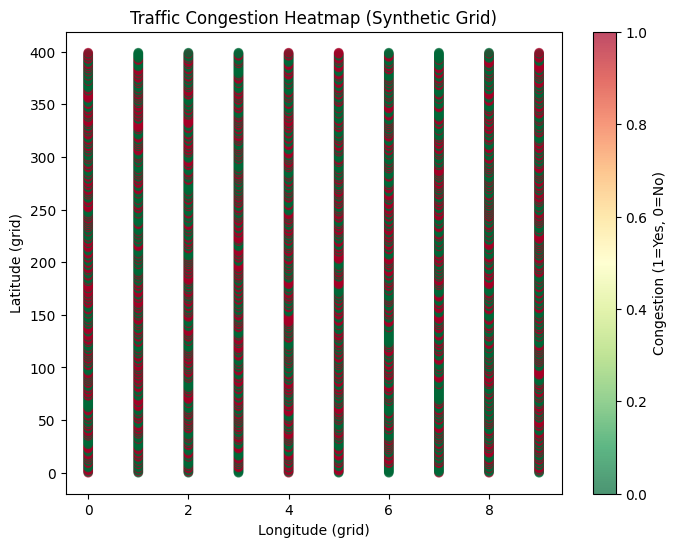

In [ ]:
# Task 3: Spatial Visualization
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Load dataset
df = pd.read_csv(url)

# Step 2: Run your trained model from Task 2
# (Assume 'model' is already trained and 'X' are your features)
df['predicted_label'] = model.predict(X)

# Step 3: Create synthetic coordinates for visualization
df['latitude'] = df.index // 10   # grid rows
df['longitude'] = df.index % 10   # grid columns

# Step 4: Plot congestion heatmap
plt.figure(figsize=(8,6))
plt.scatter(df['longitude'], df['latitude'],
            c=df['predicted_label'], cmap="RdYlGn_r", alpha=0.7)
plt.title("Traffic Congestion Heatmap (Synthetic Grid)")
plt.xlabel("Longitude (grid)")
plt.ylabel("Latitude (grid)")
plt.colorbar(label="Congestion (1=Yes, 0=No)")
plt.show()



## Task 4: Traffic System Interpretation

In this section, we explain how the AI model’s predictions can be translated into real-world traffic management and emergency response actions.

Congestion Hotspots  
  1. Adjust traffic signals dynamically (longer green lights where jams are detected).  
    a)Suggest alternate routes to drivers via navigation apps.  
  b) Deploy traffic police to manage bottlenecks in critical areas.  

2)Incident Detection (Accidents, Roadblocks)  
  a) Trigger alerts for emergency responders (ambulance, fire, police).  
  b) Inform nearby drivers to slow down or reroute.  
  c) Dispatch tow trucks or clearance teams quickly.  

3)Recurring Patterns  
  a)Identify locations with daily/evening jams.  
  b)Recommend infrastructure changes (extra lanes, flyovers, smart signals).  
  c)Improve public transport options in high-risk zones.  

4)Emergency Response Integration  
  a)Connect AI outputs with city control centers for automatic alerts.  
  b) Prioritize incidents based on severity.  
  c)Guide emergency vehicles through uncongested routes to reduce response time.  

 Summary
Traffic system interpretation bridges the gap between AI predictions and practical actions. By turning congestion and incident detection into actionable steps, cities can manage traffic more efficiently, reduce delays, and improve safety.


## Task 5: Reflection

In this section, we critically evaluate the project by identifying limitations and suggesting future improvements.
Limitations:
1)Dataset Bias  
  The dataset is primarily based on aerial imagery, which may not capture ground-level details such as pedestrian crossings, weather effects, or local traffic rules.  
2)Model Generalization
  A model trained on one city may not perform equally well in another city with different traffic behaviors and road layouts.  
3)Real-Time Deployment Challenges
  Running predictions in real time requires strong hardware and low latency. Delays could reduce the usefulness of the system during emergencies.  
4)Single Data Source
  Reliance on aerial images alone means missing out on IoT sensor data, GPS data, or CCTV feeds that could improve accuracy.  

##Future Improvements
1)Multi-Modal Data Integration
   Combine aerial imagery with IoT sensors, GPS data, and CCTV feeds for richer insights.  
2)Adaptive Learning  
   Implement online learning so the model continuously improves with new traffic data.  
3)Smart City Integration
   Connect the system with smart traffic lights, navigation apps, and emergency services for automated responses.  
4)Scalability  
   Optimize the model to handle larger datasets and multiple cities simultaneously.  
5)Weather & Seasonal Adjustments
   Incorporate weather data (rain, fog, heat) and seasonal traffic variations for more realistic predictions.  

